# Laborator 3 - Reţele Bayesiene

Un sistem de clasificare a e-mail-urilor foloseşte o reţea bayesiană pentru a evalua probabilitatea ca un e-mail să fie spam. Variabilele (toate binare, 0/1):

- $S$: e-mail-ul este spam ($S=1$) sau nu ($S=0$)
- $O$: conţine cuvântul "ofertă" ($O=1$) sau nu
- $L$: conţine link-uri ($L=1$) sau nu
- $M$: are lungime mare ($M=1$) sau nu

**Structura reţelei:** $S \to O$, $S \to L$, $S \to M$ şi $L \to M$. Cu alte cuvinte, spamul influenţează cuvântul "ofertă" şi link-urile, iar lungimea depinde atât de spam, cât şi de link-uri.

**Tabelele de probabilităţi:**

| | |
|---|---|
| $P(S=1) = 0.4$ | $P(S=0) = 0.6$ |
| $P(O=1 \mid S=1) = 0.7$ | $P(O=1 \mid S=0) = 0.1$ |
| $P(L=1 \mid S=1) = 0.8$ | $P(L=1 \mid S=0) = 0.3$ |
| $P(M=1 \mid S=1, L=1) = 0.9$ | $P(M=1 \mid S=1, L=0) = 0.5$ |
| $P(M=1 \mid S=0, L=1) = 0.6$ | $P(M=1 \mid S=0, L=0) = 0.2$ |

**Cerinţe:** a) identificaţi independenţele din reţea; b) determinaţi cum clasifică reţeaua e-mail-urile în funcţie de atributele $O$, $L$ şi $M$.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(12)

## Reprezentarea reţelei

Mai întâi desenăm graful, ca să vedem cine influenţează pe cine.

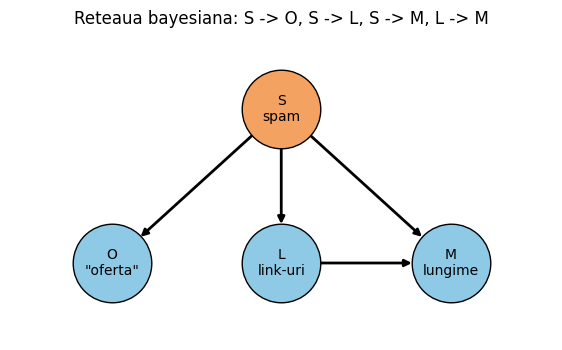

In [2]:
poz = {"S": (1.0, 1.2), "O": (0.0, 0.0), "L": (1.0, 0.0), "M": (2.0, 0.0)}
muchii = [("S", "O"), ("S", "L"), ("S", "M"), ("L", "M")]
culori = {"S": "#f4a261", "O": "#8ecae6", "L": "#8ecae6", "M": "#8ecae6"}
nume = {"S": "S\nspam", "O": "O\n\"oferta\"", "L": "L\nlink-uri", "M": "M\nlungime"}

fig, ax = plt.subplots(figsize=(7, 4))
for a, b in muchii:
    ax.annotate("", xy=poz[b], xytext=poz[a],
                arrowprops=dict(arrowstyle="-|>", lw=2, color="black",
                                shrinkA=28, shrinkB=28))
for v, (x, y) in poz.items():
    ax.scatter([x], [y], s=3200, color=culori[v], edgecolor="black", zorder=3)
    ax.text(x, y, nume[v], ha="center", va="center", fontsize=10, zorder=4)
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(-0.6, 1.8)
ax.axis("off")
ax.set_title("Reteaua bayesiana: S -> O, S -> L, S -> M, L -> M")
plt.show()

## Distribuţia comună a reţelei

Într-o reţea bayesiană, distribuţia comună se factorizează după structura grafului: fiecare variabilă este condiţionată doar de **părinţii** ei.

$$P(S, O, L, M) = P(S)\; P(O \mid S)\; P(L \mid S)\; P(M \mid S, L)$$

În loc de $2^4 - 1 = 15$ parametri liberi, avem nevoie doar de $1 + 2 + 2 + 4 = 9$ (numărul de intrări din tabelele de mai sus). Construim tabloul $P(S,O,L,M)$ cu $2\cdot2\cdot2\cdot2 = 16$ de valori, indexat ca `J[s, o, l, m]`.

In [3]:
# tabelele de probabilitati din enunt
P_S = {1: 0.4, 0: 0.6}
P_O1 = {1: 0.7, 0: 0.1}                              # P(O=1 | S)
P_L1 = {1: 0.8, 0: 0.3}                              # P(L=1 | S)
P_M1 = {(1, 1): 0.9, (1, 0): 0.5, (0, 1): 0.6, (0, 0): 0.2}   # P(M=1 | S, L)

def bern(p1, x):
    # P(X = x) pentru o variabila binara cu P(X=1) = p1
    return p1 if x == 1 else 1 - p1

def comun(s, o, l, m):
    # P(S=s, O=o, L=l, M=m) = P(S) P(O|S) P(L|S) P(M|S,L)
    return (P_S[s]
            * bern(P_O1[s], o)
            * bern(P_L1[s], l)
            * bern(P_M1[(s, l)], m))

# J[s, o, l, m]
J = np.zeros((2, 2, 2, 2))
for s, o, l, m in itertools.product([0, 1], repeat=4):
    J[s, o, l, m] = comun(s, o, l, m)

print("Suma tuturor celor 16 probabilitati:", J.sum())

Suma tuturor celor 16 probabilitati: 1.0


## a) Independenţele din reţea

### Cum le citim din graf

Folosim **proprietatea Markov locală**: fiecare variabilă este independentă de toţi *non-descendenţii* ei, dacă îi cunoaştem părinţii. Pentru verificări mai generale folosim **d-separarea**, cu trei tipare de bază pentru un drum prin reţea:

- **lanţ** $A \to B \to C$: drumul e blocat dacă observăm $B$;
- **bifurcaţie (cauză comună)** $A \leftarrow B \to C$: drumul e blocat dacă observăm $B$, altfel $A$ şi $C$ sunt dependente;
- **coliziune** $A \to B \leftarrow C$: drumul e blocat dacă **nu** observăm $B$ (nici descendenţii lui), iar observarea lui $B$ îl deschide.

### Aplicare

**$O$** are un singur părinte, $S$. Non-descendenţii lui $O$ sunt $S$, $L$ şi $M$ ($O$ nu are copii). Deci:

$$\boxed{O \perp \{L, M\} \mid S}$$

Adică, dacă ştim dacă e-mail-ul este spam, cuvântul "ofertă" nu ne mai spune nimic despre link-uri sau lungime. De aici rezultă (prin "weak union") şi consecinţele:

$$O \perp L \mid S, \qquad O \perp M \mid S, \qquad O \perp L \mid \{S, M\}, \qquad O \perp M \mid \{S, L\}$$

Dacă ne uităm la drumul $O \leftarrow S \to L$, $S$ este o **cauză comună** (bifurcaţie), deci observarea lui $S$ blochează drumul. Pentru $O \leftarrow S \to M$ e acelaşi lucru.

### Ce NU este independent

- **Dependenţe directe** (există muchie): $S$–$O$, $S$–$L$, $S$–$M$ şi $L$–$M$. În special, $L$ şi $M$ rămân dependente **chiar şi dacă ştim $S$**, pentru că $L$ este părinte al lui $M$.
- **Dependenţe marginale prin cauza comună:** $O$ şi $L$ (la fel $O$ şi $M$) sunt dependente dacă **nu** observăm $S$, pentru că drumul $O \leftarrow S \to L$ rămâne deschis. Intuitiv: dacă un e-mail conţine "ofertă", e mai probabil spam, deci e şi mai probabil să aibă link-uri.
- Nu există nicio pereche de variabile marginal independentă, deoarece graful este conex şi toate perechile sunt legate printr-un drum deschis când nu observăm nimic.

Aceasta este diferenţa faţă de Naive Bayes: aici $M$ **nu** este independent de $L$ dat $S$, iar reţeaua modelează această dependenţă.

Verificăm numeric. Două variabile (sau grupuri) $A$ şi $B$ sunt independente dat $C$ dacă $P(A,B,C)\,P(C) = P(A,C)\,P(B,C)$ pentru toate valorile.

In [4]:
axe = {"S": 0, "O": 1, "L": 2, "M": 3}

def marg(pastreaza):
    # marginala lui J pe variabilele pastrate (restul sunt sumate)
    ax_pastrate = {axe[v] for v in pastreaza}
    de_sumat = tuple(i for i in range(4) if i not in ax_pastrate)
    return J.sum(axis=de_sumat, keepdims=True)

def independente(A, B, C=()):
    # testeaza A _||_ B | C  (A, B, C sunt liste de nume de variabile)
    A, B, C = set(A), set(B), set(C)
    stanga = marg(A | B | C) * marg(C)
    dreapta = marg(A | C) * marg(B | C)
    return np.allclose(stanga, dreapta), np.abs(stanga - dreapta).max()

teste = [
    (["O"], ["L"], ["S"]),
    (["O"], ["M"], ["S"]),
    (["O"], ["L", "M"], ["S"]),
    (["O"], ["L"], ["S", "M"]),
    (["O"], ["M"], ["S", "L"]),
    (["O"], ["L"], []),
    (["O"], ["M"], []),
    (["L"], ["M"], ["S"]),
    (["S"], ["O"], []),
]

randuri = []
for A, B, C in teste:
    ok, dif = independente(A, B, C)
    cond = ("| " + ",".join(C)) if C else "(marginal)"
    randuri.append({
        "test": f"{','.join(A)} _||_ {','.join(B)} {cond}",
        "independente?": "DA" if ok else "NU",
        "diferenta maxima": f"{dif:.4f}",
    })
print(pd.DataFrame(randuri).to_string(index=False))

               test independente? diferenta maxima
       O _||_ L | S            DA           0.0000
       O _||_ M | S            DA           0.0000
     O _||_ L,M | S            DA           0.0000
     O _||_ L | S,M            DA           0.0000
     O _||_ M | S,L            DA           0.0000
O _||_ L (marginal)            NU           0.0720
O _||_ M (marginal)            NU           0.0720
       L _||_ M | S            NU           0.0302
S _||_ O (marginal)            NU           0.1440


Tabelul confirmă teoria: toate independenţele condiţionate ale lui $O$ date de $S$ ies **DA**, iar $O$–$L$, $O$–$M$ marginal, $L$–$M$ dat $S$ şi $S$–$O$ ies **NU**.

Un exemplu concret, calculat de mână, pentru $O \perp L$ :

$$P(O=1) = 0.4\cdot0.7 + 0.6\cdot0.1 = 0.34, \qquad P(L=1) = 0.4\cdot0.8 + 0.6\cdot0.3 = 0.50$$
$$P(O=1, L=1) = 0.4\cdot0.7\cdot0.8 + 0.6\cdot0.1\cdot0.3 = 0.242 \;\neq\; 0.34\cdot 0.50 = 0.17$$

Deci $O$ şi $L$ nu sunt independente marginal. Dar condiţionat de $S=1$: $P(O=1,L=1\mid S=1) = 0.7\cdot0.8 = 0.56 = P(O=1\mid S=1)\,P(L=1\mid S=1)$, deci sunt independente dat $S$.

In [5]:
# Exemplul de mana, verificat in cod
p_o = J[:, 1, :, :].sum()
p_l = J[:, :, 1, :].sum()
p_ol = J[:, 1, 1, :].sum()
print(f"P(O=1)={p_o:.3f}  P(L=1)={p_l:.3f}  P(O=1,L=1)={p_ol:.3f}  P(O=1)P(L=1)={p_o * p_l:.3f}")

p_s1 = J[1].sum()
p_ol_s1 = J[1, 1, 1, :].sum() / p_s1
p_o_s1 = J[1, 1, :, :].sum() / p_s1
p_l_s1 = J[1, :, 1, :].sum() / p_s1
print(f"Dat S=1: P(O=1,L=1|S=1)={p_ol_s1:.3f}  P(O=1|S=1)P(L=1|S=1)={p_o_s1 * p_l_s1:.3f}")

P(O=1)=0.340  P(L=1)=0.500  P(O=1,L=1)=0.242  P(O=1)P(L=1)=0.170
Dat S=1: P(O=1,L=1|S=1)=0.560  P(O=1|S=1)P(L=1|S=1)=0.560


## b) Clasificarea e-mail-urilor

Pentru un e-mail cu atributele observate $(O, L, M) = (o, l, m)$, calculăm probabilitatea de spam cu **formula lui Bayes**:

$$P(S=1 \mid o, l, m) = \frac{P(S=1, o, l, m)}{P(S=1, o, l, m) + P(S=0, o, l, m)}$$

unde fiecare termen se obţine din factorizarea reţelei:

$$P(S=s, o, l, m) = P(s)\; P(o \mid s)\; P(l \mid s)\; P(m \mid s, l)$$

**Regula de decizie:** clasificăm e-mail-ul ca **spam** dacă $P(S=1 \mid o,l,m) \ge 0.5$, altfel ca **non-spam**. Este regula care minimizează probabilitatea de eroare.

### Exemplu de calcul pentru $(O, L, M) = (1, 1, 1)$

$$P(S=1, 1,1,1) = 0.4 \cdot 0.7 \cdot 0.8 \cdot 0.9 = 0.2016$$
$$P(S=0, 1,1,1) = 0.6 \cdot 0.1 \cdot 0.3 \cdot 0.6 = 0.0108$$
$$P(S=1 \mid 1,1,1) = \frac{0.2016}{0.2016 + 0.0108} = \frac{0.2016}{0.2124} \approx 0.9492$$

Un e-mail cu "ofertă", link-uri şi lungime mare este spam cu aproximativ $95\%$ probabilitate.

### Exemplu de calcul pentru $(O, L, M) = (0, 1, 1)$

$$P(S=1, 0,1,1) = 0.4 \cdot 0.3 \cdot 0.8 \cdot 0.9 = 0.0864$$
$$P(S=0, 0,1,1) = 0.6 \cdot 0.9 \cdot 0.3 \cdot 0.6 = 0.0972$$
$$P(S=1 \mid 0,1,1) = \frac{0.0864}{0.0864 + 0.0972} \approx 0.4706$$

Fără cuvântul "ofertă", dar cu link-uri şi lungime mare, e-mail-ul este *aproape* de pragul de 50%, dar rămâne clasificat ca non-spam.

Calculăm acum toate cele 8 combinaţii cu codul.

In [6]:
def p_spam(o, l, m):
    # P(S=1 | O=o, L=l, M=m) prin formula lui Bayes
    spam = comun(1, o, l, m)
    nespam = comun(0, o, l, m)
    return spam / (spam + nespam)

def clasifica(o, l, m, prag=0.5):
    return "SPAM" if p_spam(o, l, m) >= prag else "non-spam"

randuri = []
for o, l, m in itertools.product([1, 0], repeat=3):
    randuri.append({
        "O": o, "L": l, "M": m,
        "P(S=1,o,l,m)": round(comun(1, o, l, m), 4),
        "P(S=0,o,l,m)": round(comun(0, o, l, m), 4),
        "P(o,l,m)": round(comun(1, o, l, m) + comun(0, o, l, m), 4),
        "P(S=1|o,l,m)": round(p_spam(o, l, m), 4),
        "clasa": clasifica(o, l, m),
    })
tabel = pd.DataFrame(randuri)
print(tabel.to_string(index=False))

 O  L  M  P(S=1,o,l,m)  P(S=0,o,l,m)  P(o,l,m)  P(S=1|o,l,m)    clasa
 1  1  1        0.2016        0.0108    0.2124        0.9492     SPAM
 1  1  0        0.0224        0.0072    0.0296        0.7568     SPAM
 1  0  1        0.0280        0.0084    0.0364        0.7692     SPAM
 1  0  0        0.0280        0.0336    0.0616        0.4545 non-spam
 0  1  1        0.0864        0.0972    0.1836        0.4706 non-spam
 0  1  0        0.0096        0.0648    0.0744        0.1290 non-spam
 0  0  1        0.0120        0.0756    0.0876        0.1370 non-spam
 0  0  0        0.0120        0.3024    0.3144        0.0382 non-spam


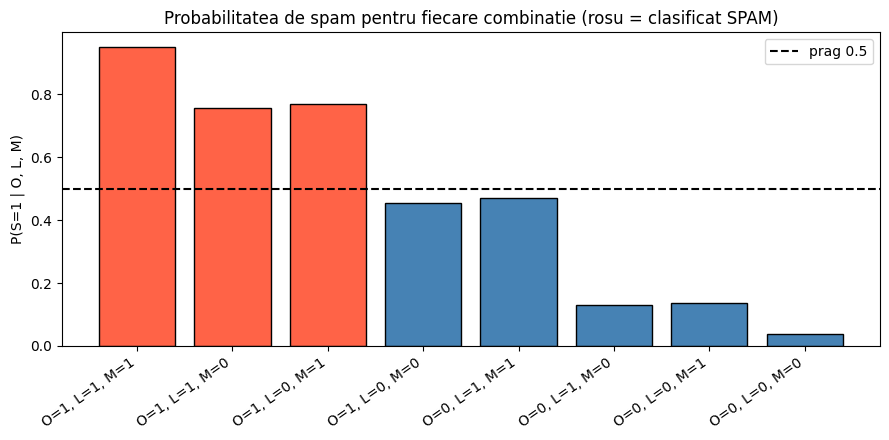

In [7]:
# grafic: probabilitatea de spam pentru fiecare combinatie de atribute
etichete = [f"O={r['O']}, L={r['L']}, M={r['M']}" for r in randuri]
probe = [r["P(S=1|o,l,m)"] for r in randuri]
culori = ["tomato" if p >= 0.5 else "steelblue" for p in probe]

plt.figure(figsize=(9, 4.5))
plt.bar(etichete, probe, color=culori, edgecolor="black")
plt.axhline(0.5, color="black", linestyle="--", label="prag 0.5")
plt.xticks(rotation=35, ha="right")
plt.ylabel("P(S=1 | O, L, M)")
plt.title("Probabilitatea de spam pentru fiecare combinatie (rosu = clasificat SPAM)")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretarea rezultatelor

Din tabel observăm că reţeaua clasifică un e-mail ca **spam** exact în cazurile:

| $O$ | $L$ | $M$ | $P(S=1\mid O,L,M)$ | Clasa |
|---|---|---|---|---|
| 1 | 1 | 1 | 0.9492 | **spam** |
| 1 | 1 | 0 | 0.7568 | **spam** |
| 1 | 0 | 1 | 0.7692 | **spam** |
| 1 | 0 | 0 | 0.4545 | non-spam |
| 0 | 1 | 1 | 0.4706 | non-spam |
| 0 | 1 | 0 | 0.1290 | non-spam |
| 0 | 0 | 1 | 0.1370 | non-spam |
| 0 | 0 | 0 | 0.0382 | non-spam |

Deci regula rezultată este:

$$\text{spam} \iff O = 1 \;\text{ şi }\; (L = 1 \text{ sau } M = 1)$$

adică un e-mail cu "ofertă" este spam dacă are *cel puţin încă un semn* (link-uri sau lungime mare).

**De ce?** Putem citi efectul fiecărui atribut în formă de şanse (*odds*). Şansele a priori sunt $\frac{0.4}{0.6} = \frac23$.

- **"Ofertă"** este cea mai puternică dovadă: raportul de verosimilitate este $\frac{P(O=1\mid S=1)}{P(O=1\mid S=0)} = \frac{0.7}{0.1} = 7$. Absenţa ei, $\frac{0.3}{0.9} = \frac13$, împinge puternic spre non-spam.
- **Link-urile** au raportul $\frac{0.8}{0.3} \approx 2.67$ când sunt prezente.
- **Lungimea** depinde de $L$. Dacă $L=1$, $M=1$ are raportul $\frac{0.9}{0.6} = 1.5$, iar $M=0$ are $\frac{0.1}{0.4} = 0.25$. Dacă $L=0$, $M=1$ are raportul $\frac{0.5}{0.2} = 2.5$, iar $M=0$ are $\frac{0.5}{0.8} = 0.625$. Pentru că $M$ depinde şi de $L$, nu putem trata $M$ ca pe o dovadă independentă (ca la Naive Bayes). De aceea contribuţia lui $M$ diferă după valoarea lui $L$.

Cazurile **la limită** sunt $(1,0,0)$ cu $0.4545$ şi $(0,1,1)$ cu $0.4706$, ambele apropiate de 0.5. Dacă am trece pragul la, de exemplu, $0.45$, primul ar deveni spam, iar o schimbare mică în tabele ar putea inversa decizia. Pentru un filtru de e-mail, unde un fals pozitiv (un mesaj legitim trimis în spam) e mai grav decât un spam ratat, se poate folosi un prag mai mare de 0.5.

### Verificare prin simulare

Generăm un număr mare de e-mail-uri **parcurgând reţeaua de la părinţi la copii** (întâi $S$, apoi $O$ şi $L$ dat $S$, apoi $M$ dat $S$ şi $L$), apoi estimăm $P(S=1 \mid O,L,M)$ ca proporţia de spamuri dintre e-mail-urile cu acelaşi tipar de atribute.

In [8]:
n = 2_000_000

S = (np.random.rand(n) < P_S[1]).astype(int)
O = (np.random.rand(n) < np.where(S == 1, P_O1[1], P_O1[0])).astype(int)
L = (np.random.rand(n) < np.where(S == 1, P_L1[1], P_L1[0])).astype(int)

# P(M=1 | S, L) din tabel, ales pentru fiecare e-mail
pM = np.array([[P_M1[(0, 0)], P_M1[(0, 1)]],
               [P_M1[(1, 0)], P_M1[(1, 1)]]])   # pM[s, l]
M_ = (np.random.rand(n) < pM[S, L]).astype(int)

df = pd.DataFrame({"S": S, "O": O, "L": L, "M": M_})
sim = df.groupby(["O", "L", "M"])["S"].agg(["mean", "size"]).reset_index()
sim.columns = ["O", "L", "M", "simulare", "nr_emailuri"]
sim["teoretic"] = [p_spam(o, l, m) for o, l, m in zip(sim["O"], sim["L"], sim["M"])]
sim["diferenta"] = (sim["simulare"] - sim["teoretic"]).abs()
print(sim.sort_values(["O", "L", "M"], ascending=False).round(4).to_string(index=False))

 O  L  M  simulare  nr_emailuri  teoretic  diferenta
 1  1  1    0.9488       424525    0.9492     0.0003
 1  1  0    0.7579        59448    0.7568     0.0011
 1  0  1    0.7700        73295    0.7692     0.0008
 1  0  0    0.4581       123135    0.4545     0.0036
 0  1  1    0.4700       366350    0.4706     0.0005
 0  1  0    0.1294       148952    0.1290     0.0004
 0  0  1    0.1365       175710    0.1370     0.0005
 0  0  0    0.0380       628585    0.0382     0.0002


Valorile din simulare coincid cu cele calculate cu formula lui Bayes (diferenţe de ordinul miimilor), deci calculele sunt corecte.

### Concluzie

- **a)** Singura independenţă structurală din reţea este cea a lui $O$ faţă de $\{L, M\}$ **dat $S$** (şi consecinţele ei). Celelalte variabile sunt dependente, iar $L$ şi $M$ rămân dependente chiar şi dat $S$.
- **b)** Reţeaua clasifică un e-mail ca spam exact când conţine "ofertă" **şi** are link-uri sau este lung. Probabilităţile se obţin din $P(S,O,L,M) = P(S)P(O\mid S)P(L\mid S)P(M\mid S,L)$ şi formula lui Bayes.